# RAG Pipeline Experiment Visualization

Visualizations of improvement across 7 experiment rounds (0–6, 182 total configurations),
highlighting the key findings from our systematic RAG pipeline optimization.

In [90]:
# !pip install seaborn

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import json
import re
import ast
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', font_scale=1.1)
PALETTE = sns.color_palette('muted')
ACCENT = PALETTE[0]
COLORS = {'ret': PALETTE[0], 'gen': PALETTE[1], 'recall': PALETTE[2]}

def extract_embedding(cfg_str):
    if 'MiniLM-L6' in str(cfg_str):
        return 'HF MiniLM-L6'
    if 'mpnet-base' in str(cfg_str):
        return 'HF mpnet-base'
    if 'llm-embedder' in str(cfg_str):
        return 'HF llm-embedder'
    if 'tgpt' in str(cfg_str) or 'OpenAI' in str(cfg_str):
        return 'OpenAI tgpt'
    return 'Unknown'

def extract_search(cfg_str):
    s = str(cfg_str)
    k_match = re.search(r"'k':\s*(\d+)", s) or re.search(r'"k":\s*(\d+)', s)
    k = k_match.group(1) if k_match else '10'
    if 'mmr' in s:
        return f'mmr k={k}'
    return f'similarity k={k}'

def extract_reranker(cfg_str):
    s = str(cfg_str)
    if 'bge-reranker' in s:
        name = 'bge-reranker-v2-m3'
    elif 'MiniLM-L12' in s:
        name = 'ms-marco-L12'
    elif 'MiniLM-L6' in s:
        name = 'ms-marco-L6'
    else:
        name = 'Unknown'
    top_n_match = re.search(r"'top_n':\s*(\d+)", s) or re.search(r'"top_n":\s*(\d+)', s)
    top_n = int(top_n_match.group(1)) if top_n_match else 5
    return name, top_n

def extract_generator(name):
    mapping = {
        'api-mistral-small-3.2-2506': 'mistral-small',
        'api-gpt-oss-120b': 'gpt-oss-120b',
        'api-gemma-4-26b': 'gemma-4-26b',
        'api-llama-4-scout': 'llama-4-scout',
    }
    return mapping.get(name, name)

def parse_json_metric(val):
    """Extract 'value' from JSON-encoded metric fields (if present)."""
    if isinstance(val, (int, float)):
        return val
    try:
        d = json.loads(str(val).replace("'", '"'))
        return d.get('value', val)
    except (json.JSONDecodeError, TypeError):
        return val

METRIC_COLS = [
    'F1@5', 'Precision@5', 'Recall@5', 'Retrieval Score',
    'Correctness (pass rate)', 'Faithfulness (pass rate)',
    'Completeness (normalized)', 'Generation Score (3 released)'
]

COL_ALIASES = {
    'F1_at_5': 'F1@5',
    'Precision_at_5': 'Precision@5',
    'Recall_at_5': 'Recall@5',
    'Correctness_pass_rate': 'Correctness (pass rate)',
    'Faithfulness_pass_rate': 'Faithfulness (pass rate)',
    'Completeness_normalized': 'Completeness (normalized)',
    'Generation_Score_3_released': 'Generation Score (3 released)',
}

def load_round(path, round_num):
    df = pd.read_csv(path)
    df.rename(columns=COL_ALIASES, inplace=True)
    df['round'] = round_num
    for col in METRIC_COLS:
        if col in df.columns:
            df[col] = df[col].apply(parse_json_metric).astype(float)
    df['embedding'] = df['embedding_cfg'].apply(extract_embedding)
    df['search'] = df['search_cfg'].apply(extract_search)
    rr = df['reranker_cfg'].apply(extract_reranker)
    df['reranker'] = rr.apply(lambda x: x[0])
    df['top_n'] = rr.apply(lambda x: x[1])
    df['generator'] = df['model_name'].apply(extract_generator)
    return df

r0 = load_round('../misc/logs/experiments_0.csv', 0)
r1 = load_round('experiments_1.csv', 1)
r2 = load_round('experiments_2.csv', 2)
r3 = load_round('experiments_3.csv', 3)
r4 = load_round('experiments_4.csv', 4)
r5 = load_round('experiments_5.csv', 5)
r6 = load_round('experiments_6.csv', 6)

df = pd.concat([r0, r1, r2, r3, r4, r5, r6], ignore_index=True)

df.rename(columns={
    'Retrieval Score': 'ret_score',
    'Generation Score (3 released)': 'gen_score',
    'Recall@5': 'recall',
    'Precision@5': 'precision',
    'F1@5': 'f1',
    'Correctness (pass rate)': 'correctness',
    'Faithfulness (pass rate)': 'faithfulness',
    'Completeness (normalized)': 'completeness',
}, inplace=True)

print(f'Loaded {len(df)} total runs across 7 rounds (0-6)')
print(df.groupby('round')[['ret_score', 'gen_score']].agg(['mean', 'max']).round(3))
print(f'\nConfig columns: generator, chunk_size, embedding, search, reranker, top_n')

Loaded 182 total runs across 7 rounds (0-6)
      ret_score        gen_score       
           mean    max      mean    max
round                                  
0         0.786  0.813     0.869  0.884
1         0.259  0.450     0.837  0.902
2         0.405  0.458     0.889  0.939
3         0.439  0.542     0.903  0.967
4         0.138  0.172     0.874  0.881
5         0.453  0.495     0.932  0.967
6         0.499  0.509     0.939  0.957

Config columns: generator, chunk_size, embedding, search, reranker, top_n


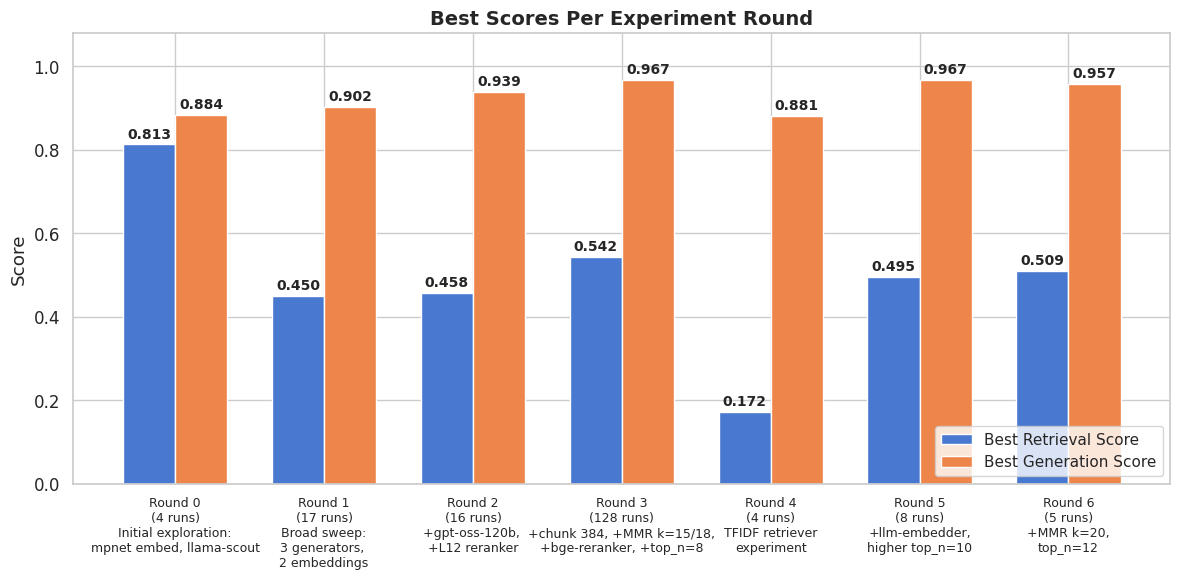

In [112]:
# --- Plot 1: Best Scores Per Experiment Round ---

round_labels = {
    0: 'Round 0\n(4 runs)\nInitial exploration:\nmpnet embed, llama-scout',
    1: 'Round 1\n(17 runs)\nBroad sweep:\n3 generators, \n2 embeddings',
    2: 'Round 2\n(16 runs)\n+gpt-oss-120b, \n+L12 reranker',
    3: 'Round 3\n(128 runs)\n+chunk 384, +MMR k=15/18,\n+bge-reranker, +top_n=8',
    4: 'Round 4\n(4 runs)\nTFIDF retriever\nexperiment',
    5: 'Round 5\n(8 runs)\n+llm-embedder,\nhigher top_n=10',
    6: 'Round 6\n(5 runs)\n+MMR k=20,\ntop_n=12',
}

best_per_round = df.groupby('round').agg(
    best_ret=('ret_score', 'max'),
    best_gen=('gen_score', 'max'),
    n_runs=('ret_score', 'count'),
).reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(best_per_round))
w = 0.35

bars_ret = ax.bar(x - w/2, best_per_round['best_ret'], w,
                   label='Best Retrieval Score', color=COLORS['ret'], edgecolor='white')
bars_gen = ax.bar(x + w/2, best_per_round['best_gen'], w,
                   label='Best Generation Score', color=COLORS['gen'], edgecolor='white')

for bar in bars_ret:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
for bar in bars_gen:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([round_labels[r] for r in best_per_round['round']], fontsize=9)
ax.set_ylabel('Score')
ax.set_title('Best Scores Per Experiment Round', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.set_ylim(0, 1.08)


plt.tight_layout()
plt.savefig('plots/01_best_per_round.png', dpi=150, bbox_inches='tight')
plt.show()

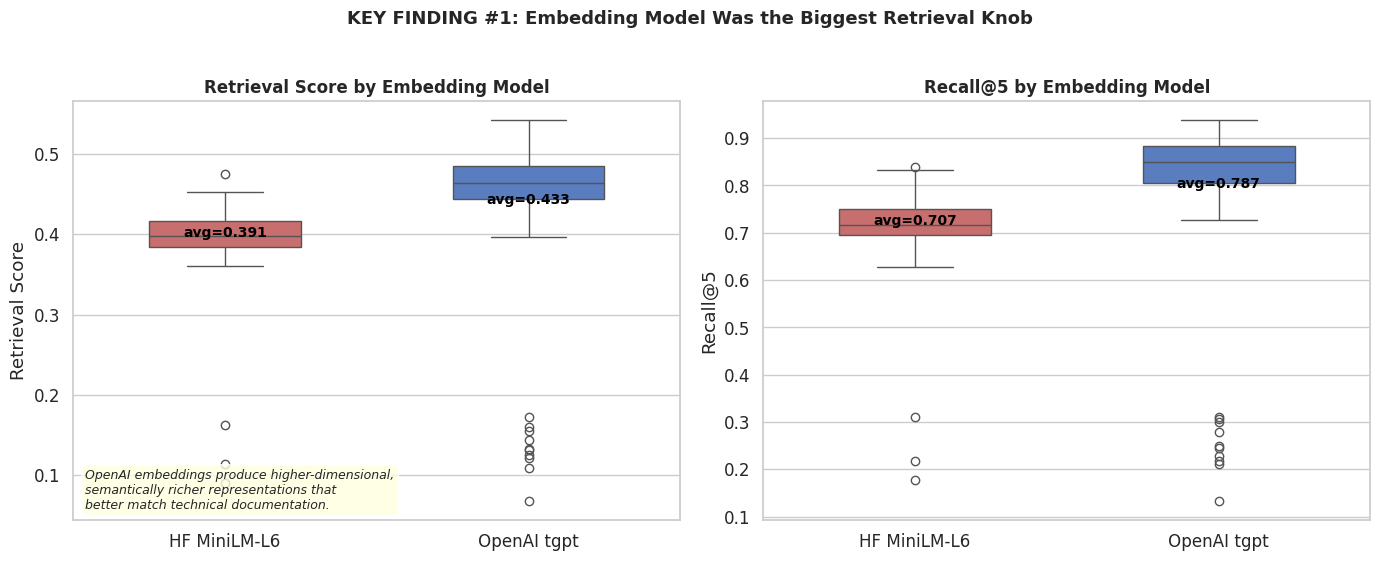

In [93]:
# --- Plot 2: Embedding Model Impact (Key Finding #1) ---

emb_mask = df['embedding'].isin(['OpenAI tgpt', 'HF MiniLM-L6'])
emb_df = df[emb_mask].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: box plot of Retrieval Score
order = ['HF MiniLM-L6', 'OpenAI tgpt']
bp = sns.boxplot(data=emb_df, x='embedding', y='ret_score', order=order,
                 palette=[PALETTE[3], PALETTE[0]], ax=axes[0], width=0.5)
means = emb_df.groupby('embedding')['ret_score'].mean()
for i, emb in enumerate(order):
    axes[0].text(i, means[emb] + 0.002, f'avg={means[emb]:.3f}',
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')
axes[0].set_title('Retrieval Score by Embedding Model', fontsize=12, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Retrieval Score')

# Right: box plot of Recall@5
sns.boxplot(data=emb_df, x='embedding', y='recall', order=order,
            palette=[PALETTE[3], PALETTE[0]], ax=axes[1], width=0.5)
means_r = emb_df.groupby('embedding')['recall'].mean()
for i, emb in enumerate(order):
    axes[1].text(i, means_r[emb] + 0.002, f'avg={means_r[emb]:.3f}',
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')
axes[1].set_title('Recall@5 by Embedding Model', fontsize=12, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Recall@5')

fig.suptitle('KEY FINDING #1: Embedding Model Was the Biggest Retrieval Knob',
             fontsize=13, fontweight='bold', y=1.02)

axes[0].annotate(
    'OpenAI embeddings produce higher-dimensional,\n'
    'semantically richer representations that\n'
    'better match technical documentation.',
    xy=(0.02, 0.02), xycoords='axes fraction', fontsize=9, fontstyle='italic',
    va='bottom', bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('plots/02_embedding_impact.png', dpi=150, bbox_inches='tight')
plt.show()

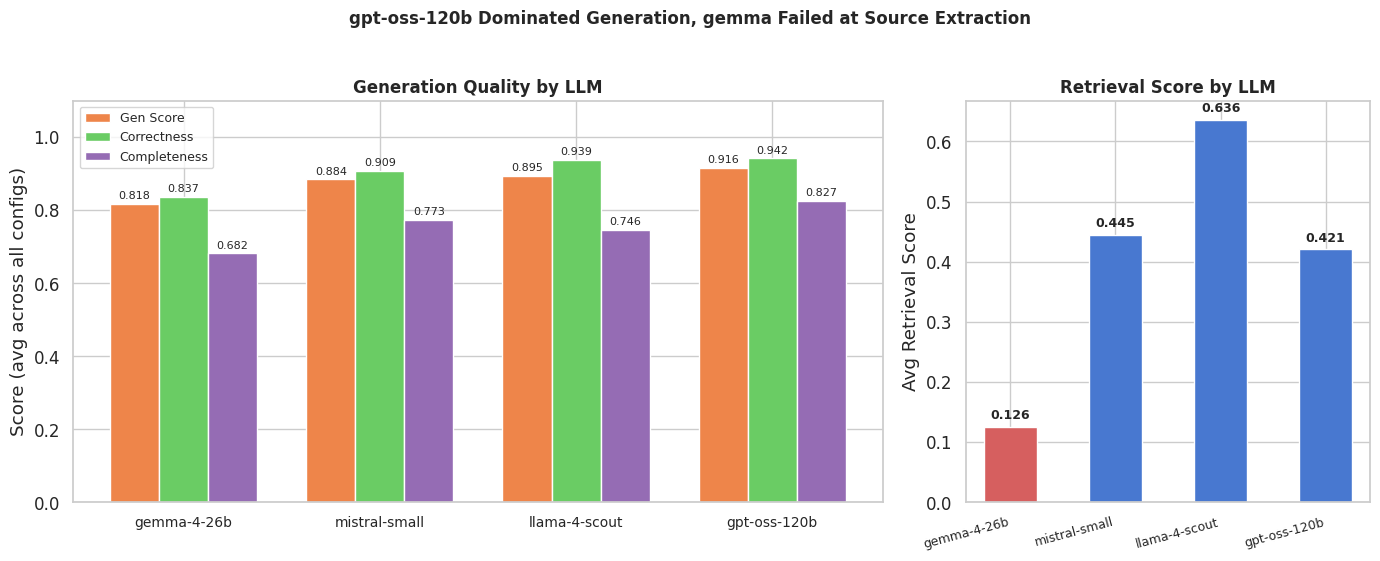

In [94]:
# --- Plot 3: Generator Model Comparison (Key Findings #2 & #6) ---

gen_order = ['gemma-4-26b', 'mistral-small', 'llama-4-scout', 'gpt-oss-120b']
gen_stats = df.groupby('generator').agg(
    gen_score=('gen_score', 'mean'),
    correctness=('correctness', 'mean'),
    completeness=('completeness', 'mean'),
    ret_score=('ret_score', 'mean'),
    n=('gen_score', 'count'),
).reindex(gen_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [2, 1]})

# Left: generation metrics
x = np.arange(len(gen_order))
w = 0.25
axes[0].bar(x - w, gen_stats['gen_score'], w, label='Gen Score', color=PALETTE[1])
axes[0].bar(x,     gen_stats['correctness'], w, label='Correctness', color=PALETTE[2])
axes[0].bar(x + w, gen_stats['completeness'], w, label='Completeness', color=PALETTE[4])

for i, (gs, cr, cm) in enumerate(zip(gen_stats['gen_score'], gen_stats['correctness'], gen_stats['completeness'])):
    axes[0].text(i - w, gs + 0.008, f'{gs:.3f}', ha='center', va='bottom', fontsize=8)
    axes[0].text(i,     cr + 0.008, f'{cr:.3f}', ha='center', va='bottom', fontsize=8)
    axes[0].text(i + w, cm + 0.008, f'{cm:.3f}', ha='center', va='bottom', fontsize=8)

axes[0].set_xticks(x)
axes[0].set_xticklabels(gen_order, fontsize=10)
axes[0].set_ylabel('Score (avg across all configs)')
axes[0].set_title('Generation Quality by LLM', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 1.1)

# Right: retrieval score (showing gemma failure)
bar_colors = [PALETTE[3] if g == 'gemma-4-26b' else PALETTE[0] for g in gen_order]
bars = axes[1].bar(x, gen_stats['ret_score'], 0.5, color=bar_colors, edgecolor='white')
for i, v in enumerate(gen_stats['ret_score']):
    axes[1].text(i, v + 0.008, f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

axes[1].set_xticks(x)
axes[1].set_xticklabels(gen_order, fontsize=9, rotation=15, ha='right')
axes[1].set_ylabel('Avg Retrieval Score')
axes[1].set_title('Retrieval Score by LLM', fontsize=12, fontweight='bold')

# axes[1].annotate(
#     'gemma-4-26b failed at\nstructured source extraction\n(regex parsing failures)',
#     xy=(0, gen_stats.loc['gemma-4-26b', 'ret_score']),
#     xytext=(1.2, 0.22),
#     arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
#     fontsize=9, color='red', fontweight='bold',
#     bbox=dict(boxstyle='round,pad=0.3', facecolor='#ffe0e0', alpha=0.9))

fig.suptitle('gpt-oss-120b Dominated Generation, gemma Failed at Source Extraction',
             fontsize=12, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('plots/03_generator_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

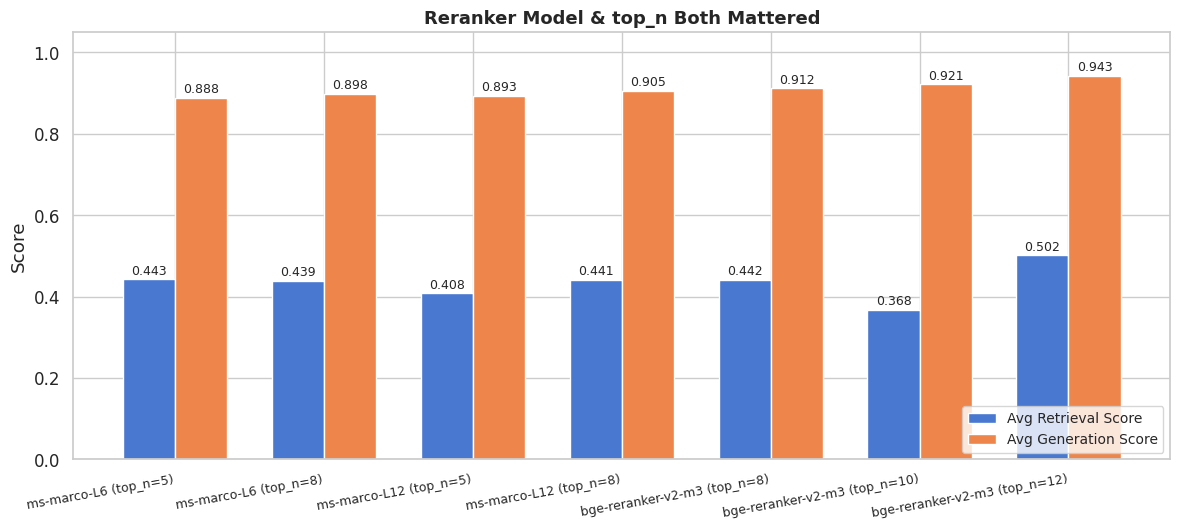

In [95]:
# --- Plot 4: Reranker Progression (Key Findings #3 & #7) ---

rr_df = df[df['generator'] != 'gemma-4-26b'].copy()
rr_df['reranker_label'] = rr_df['reranker'] + ' (top_n=' + rr_df['top_n'].astype(str) + ')'

label_order = [
    'ms-marco-L6 (top_n=5)',
    'ms-marco-L6 (top_n=8)',
    'ms-marco-L12 (top_n=5)',
    'ms-marco-L12 (top_n=8)',
    'bge-reranker-v2-m3 (top_n=8)',
    'bge-reranker-v2-m3 (top_n=10)',
    'bge-reranker-v2-m3 (top_n=12)',
]
rr_df = rr_df[rr_df['reranker_label'].isin(label_order)]

rr_stats = rr_df.groupby('reranker_label').agg(
    ret_score=('ret_score', 'mean'),
    gen_score=('gen_score', 'mean'),
    n=('ret_score', 'count'),
).reindex(label_order).dropna()

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(rr_stats))
w = 0.35

b1 = ax.bar(x - w/2, rr_stats['ret_score'], w, label='Avg Retrieval Score', color=COLORS['ret'])
b2 = ax.bar(x + w/2, rr_stats['gen_score'], w, label='Avg Generation Score', color=COLORS['gen'])

for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(rr_stats.index, fontsize=9, rotation=10, ha='right')
ax.set_ylabel('Score')
ax.set_title('Reranker Model & top_n Both Mattered',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='lower right')
ax.set_ylim(0, 1.05)

# ax.annotate(
#     'Upgrading reranker from L6 to bge-v2-m3\n'
#     'and increasing top_n from 5 to 8 gave\n'
#     'consistent gains on both metrics.',
#     xy=(0.01, 0.95), xycoords='axes fraction', fontsize=9, fontstyle='italic',
#     va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('plots/04_reranker_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

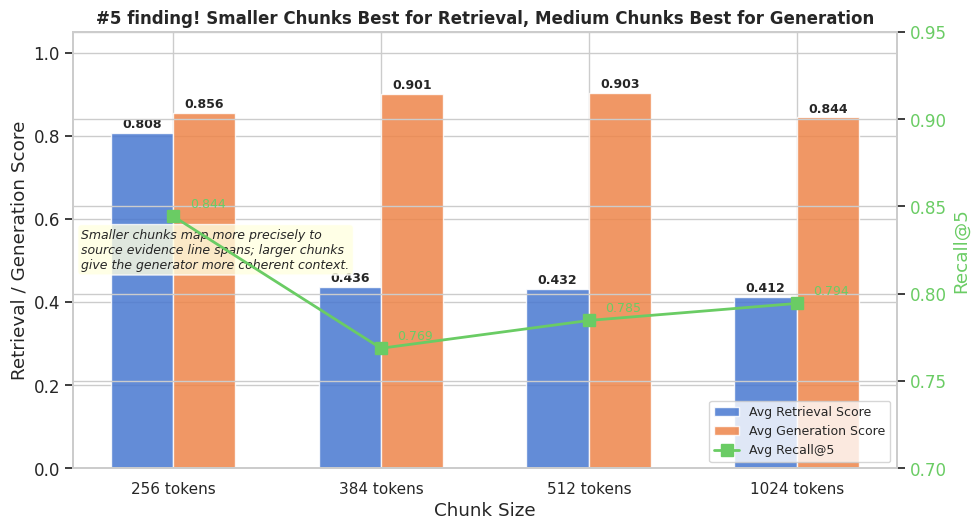

In [96]:
# --- Plot 5: Chunk Size Trade-off (Key Finding #4) ---

chunk_df = df[df['generator'] != 'gemma-4-26b'].copy()
chunk_stats = chunk_df.groupby('chunk_size').agg(
    ret_score=('ret_score', 'mean'),
    gen_score=('gen_score', 'mean'),
    recall=('recall', 'mean'),
    n=('ret_score', 'count'),
).reset_index().sort_values('chunk_size')

fig, ax1 = plt.subplots(figsize=(10, 5.5))
ax2 = ax1.twinx()

x = np.arange(len(chunk_stats))
w = 0.3

b1 = ax1.bar(x - w/2, chunk_stats['ret_score'], w, label='Avg Retrieval Score',
             color=COLORS['ret'], alpha=0.85)
b2 = ax1.bar(x + w/2, chunk_stats['gen_score'], w, label='Avg Generation Score',
             color=COLORS['gen'], alpha=0.85)

for bar in b1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in b2:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.plot(x, chunk_stats['recall'], 's-', color=COLORS['recall'], linewidth=2,
         markersize=8, label='Avg Recall@5', zorder=5)
for xi, v in zip(x, chunk_stats['recall']):
    ax2.text(xi + 0.08, v + 0.005, f'{v:.3f}', fontsize=9, color=COLORS['recall'])

ax1.set_xticks(x)
ax1.set_xticklabels(chunk_stats['chunk_size'].astype(str) + ' tokens', fontsize=11)
ax1.set_xlabel('Chunk Size')
ax1.set_ylabel('Retrieval / Generation Score')
ax2.set_ylabel('Recall@5', color=COLORS['recall'])
ax2.tick_params(axis='y', labelcolor=COLORS['recall'])

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', fontsize=9)


ax1.set_ylim(0, 1.05)
ax2.set_ylim(0.7, 0.95)
ax1.set_title('#5 finding! Smaller Chunks Best for Retrieval, Medium Chunks Best for Generation',
              fontsize=12, fontweight='bold')

ax1.annotate(
    'Smaller chunks map more precisely to\n'
    'source evidence line spans; larger chunks\n'
    'give the generator more coherent context.',
    xy=(0.01, 0.55), xycoords='axes fraction', fontsize=9, fontstyle='italic',
    va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('plots/05_chunk_size_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()

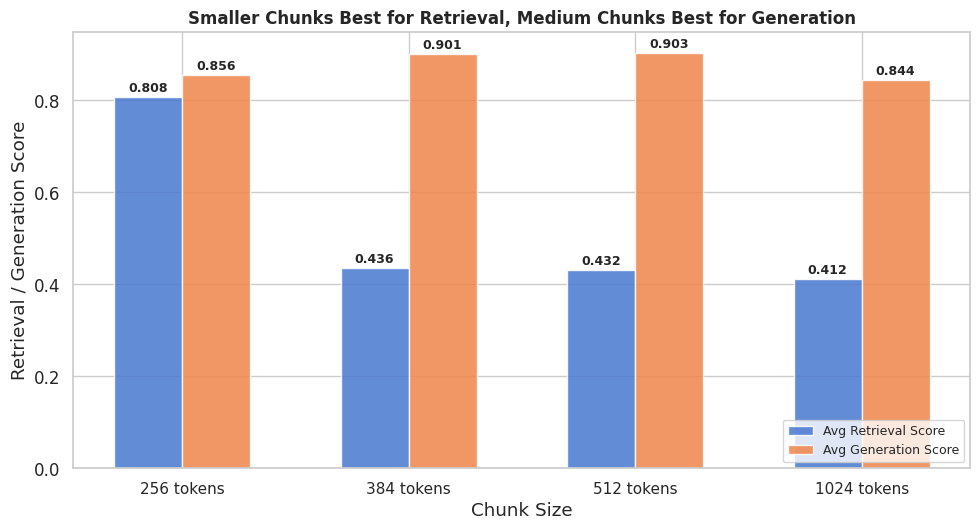

In [97]:
# --- Plot 5: Chunk Size Trade-off (Key Finding #4) ---

chunk_df = df[df['generator'] != 'gemma-4-26b'].copy()
chunk_stats = chunk_df.groupby('chunk_size').agg(
    ret_score=('ret_score', 'mean'),
    gen_score=('gen_score', 'mean'),
    recall=('recall', 'mean'),
    n=('ret_score', 'count'),
).reset_index().sort_values('chunk_size')

fig, ax1 = plt.subplots(figsize=(10, 5.5))
# ax2 = ax1.twinx()

x = np.arange(len(chunk_stats))
w = 0.3

b1 = ax1.bar(x - w/2, chunk_stats['ret_score'], w, label='Avg Retrieval Score',
             color=COLORS['ret'], alpha=0.85)
b2 = ax1.bar(x + w/2, chunk_stats['gen_score'], w, label='Avg Generation Score',
             color=COLORS['gen'], alpha=0.85)

for bar in b1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in b2:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# ax2.plot(x, chunk_stats['recall'], 's-', color=COLORS['recall'], linewidth=2,
#          markersize=8, label='Avg Recall@5', zorder=5)
# for xi, v in zip(x, chunk_stats['recall']):
#     ax2.text(xi + 0.08, v + 0.005, f'{v:.3f}', fontsize=9, color=COLORS['recall'])

ax1.set_xticks(x)
ax1.set_xticklabels(chunk_stats['chunk_size'].astype(str) + ' tokens', fontsize=11)
ax1.set_xlabel('Chunk Size')
ax1.set_ylabel('Retrieval / Generation Score')
# ax2.set_ylabel('Recall@5', color=COLORS['recall'])
# ax2.tick_params(axis='y', labelcolor=COLORS['recall'])

lines1, labels1 = ax1.get_legend_handles_labels()
# lines2, labels2 = ax2.get_legend_handles_labels()
# ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', fontsize=9)

ax1.legend(lines1, labels1, loc='lower right', fontsize=9)

# ax1.set_ylim(0, 1.05)
# ax2.set_ylim(0.7, 0.95)
ax1.set_title('Smaller Chunks Best for Retrieval, Medium Chunks Best for Generation',
              fontsize=12, fontweight='bold')

# ax1.annotate(
#     'Smaller chunks map more precisely to\n'
#     'source evidence line spans; larger chunks\n'
#     'give the generator more coherent context.',
#     xy=(0.01, 0.55), xycoords='axes fraction', fontsize=9, fontstyle='italic',
#     va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('plots/05_chunk_size_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()

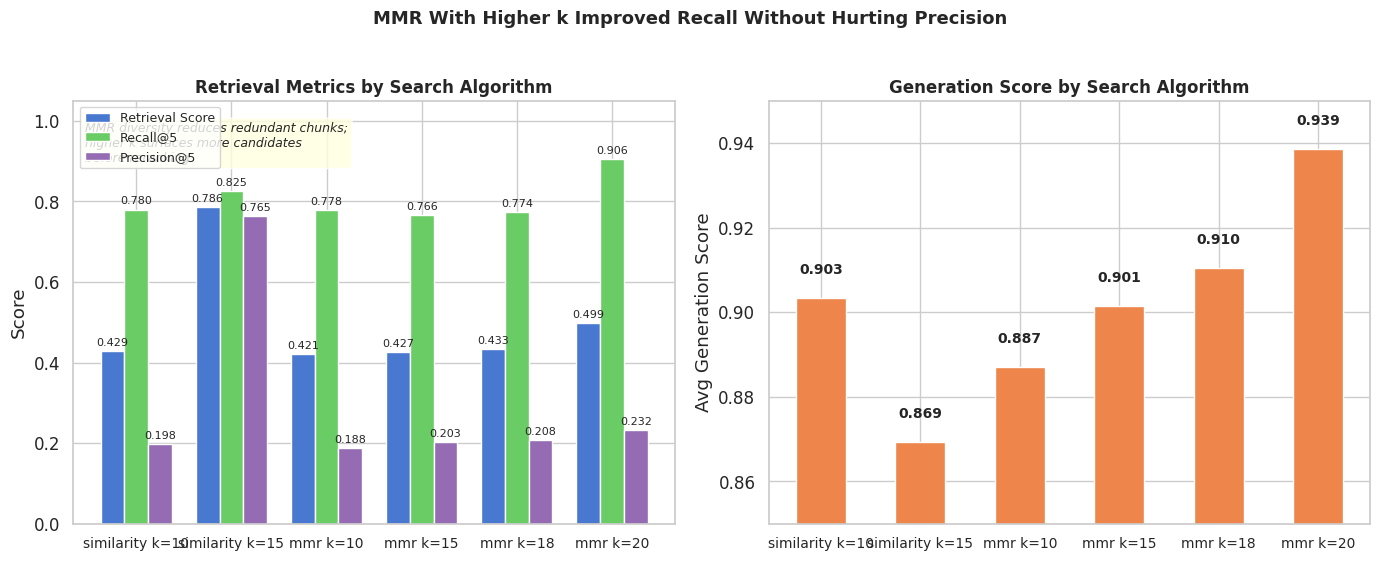

In [98]:
# --- Plot 6: MMR vs Similarity Search (Key Finding #5) ---

search_df = df[(df['generator'] != 'gemma-4-26b')].copy()
search_order = ['similarity k=10', 'similarity k=15', 'mmr k=10', 'mmr k=15', 'mmr k=18', 'mmr k=20']
search_df = search_df[search_df['search'].isin(search_order)]

search_stats = search_df.groupby('search').agg(
    ret_score=('ret_score', 'mean'),
    recall=('recall', 'mean'),
    precision=('precision', 'mean'),
    gen_score=('gen_score', 'mean'),
    n=('ret_score', 'count'),
).reindex(search_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

x = np.arange(len(search_stats))
w = 0.25

# Left: Retrieval metrics
axes[0].bar(x - w, search_stats['ret_score'], w, label='Retrieval Score', color=COLORS['ret'])
axes[0].bar(x,     search_stats['recall'], w, label='Recall@5', color=COLORS['recall'])
axes[0].bar(x + w, search_stats['precision'], w, label='Precision@5', color=PALETTE[4])

for i, (r, rc, p) in enumerate(zip(search_stats['ret_score'], search_stats['recall'], search_stats['precision'])):
    axes[0].text(i - w, r + 0.008, f'{r:.3f}', ha='center', va='bottom', fontsize=8)
    axes[0].text(i,     rc + 0.008, f'{rc:.3f}', ha='center', va='bottom', fontsize=8)
    axes[0].text(i + w, p + 0.008, f'{p:.3f}', ha='center', va='bottom', fontsize=8)

axes[0].set_xticks(x)
axes[0].set_xticklabels(search_order, fontsize=10)
axes[0].set_ylabel('Score')
axes[0].set_title('Retrieval Metrics by Search Algorithm', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 1.05)

# Right: Generation Score
bars = axes[1].bar(x, search_stats['gen_score'], 0.5, color=COLORS['gen'], edgecolor='white')
for i, v in enumerate(search_stats['gen_score']):
    axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(search_order, fontsize=10)
axes[1].set_ylabel('Avg Generation Score')
axes[1].set_title('Generation Score by Search Algorithm', fontsize=12, fontweight='bold')
axes[1].set_ylim(0.85, 0.95)

fig.suptitle('MMR With Higher k Improved Recall Without Hurting Precision',
             fontsize=13, fontweight='bold', y=1.02)

axes[0].annotate(
    'MMR diversity reduces redundant chunks;\n'
    'higher k surfaces more candidates\n'
    'before reranking.',
    xy=(0.02, 0.95), xycoords='axes fraction', fontsize=9, fontstyle='italic',
    va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('plots/06_search_algorithm.png', dpi=150, bbox_inches='tight')
plt.show()

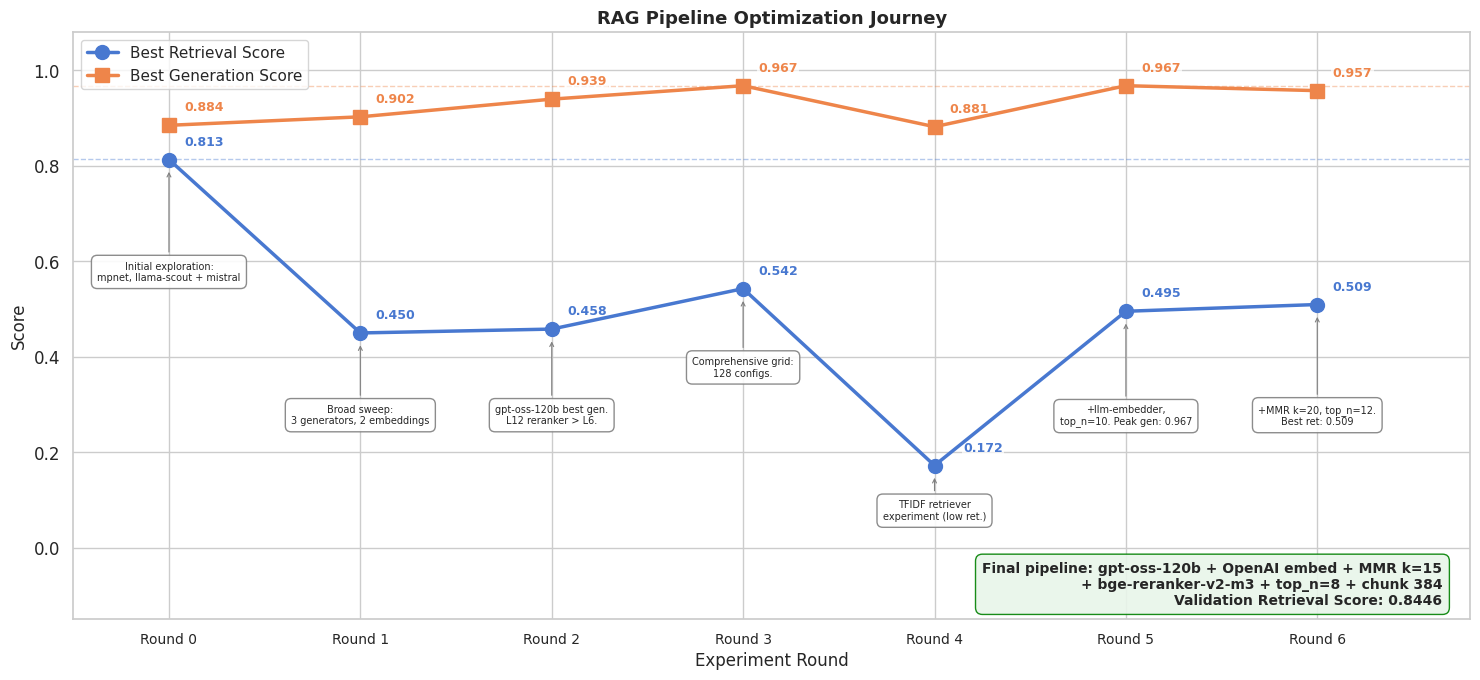

In [125]:
# --- Plot 7: Overall Improvement Timeline ---

timeline_data = best_per_round.copy()

annotations = {
    0: 'Initial exploration:\nmpnet, llama-scout + mistral',
    1: 'Broad sweep:\n3 generators, 2 embeddings',
    2: 'gpt-oss-120b best gen.\nL12 reranker > L6.',
    3: 'Comprehensive grid:\n128 configs.',
    4: 'TFIDF retriever\nexperiment (low ret.)',
    5: '+llm-embedder,\ntop_n=10. Peak gen: 0.967',
    6: '+MMR k=20, top_n=12.\nBest ret: 0.509',
}

fig, ax = plt.subplots(figsize=(15, 7))

rounds = timeline_data['round'].values
ret_vals = timeline_data['best_ret'].values
gen_vals = timeline_data['best_gen'].values

ax.plot(rounds, ret_vals, 'o-', color=COLORS['ret'], linewidth=2.5, markersize=10,
        label='Best Retrieval Score', zorder=5)
ax.plot(rounds, gen_vals, 's-', color=COLORS['gen'], linewidth=2.5, markersize=10,
        label='Best Generation Score', zorder=5)

ret_x_offsets = [0.08, 0.08, 0.08, 0.08, 0.15, 0.08, 0.08]
for i, r in enumerate(rounds):
    ret_y_off = 0.03 if ret_vals[i] < gen_vals[i] else -0.04
    gen_y_off = 0.03 if gen_vals[i] > ret_vals[i] else 0.04
    ax.text(r + ret_x_offsets[i], ret_vals[i] + ret_y_off, f'{ret_vals[i]:.3f}',
            fontsize=9, fontweight='bold', color=COLORS['ret'],
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1))
    ax.text(r + 0.08, gen_vals[i] + gen_y_off, f'{gen_vals[i]:.3f}',
            fontsize=9, fontweight='bold', color=COLORS['gen'],
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1))

y_offsets = [0.60, 0.30, 0.30, 0.40, 0.10, 0.30, 0.30]
for i, r in enumerate(rounds):
    ax.annotate(annotations[r],
                xy=(r, min(ret_vals[i], gen_vals[i]) - 0.02),
                xytext=(r, y_offsets[i]),
                fontsize=7, ha='center', va='top',
                bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                          edgecolor='gray', alpha=0.9),
                arrowprops=dict(arrowstyle='->', color='gray', lw=0.8))

ax.axhline(y=0.967, color=COLORS['gen'], linestyle='--', alpha=0.4, linewidth=1)
ax.axhline(y=0.813, color=COLORS['ret'], linestyle='--', alpha=0.4, linewidth=1)
# ax.text(6.3, 0.975, 'Peak Gen: 0.967', fontsize=8, color=COLORS['gen'], va='center')

ax.set_xlabel('Experiment Round', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('RAG Pipeline Optimization Journey',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper left', fontsize=11)
ax.set_xticks(rounds)
ax.set_xticklabels([f'Round {r}' for r in rounds], fontsize=10)
ax.set_ylim(-0.15, 1.08)
ax.set_xlim(-0.5, 6.8)

ax.annotate(
    'Final pipeline: gpt-oss-120b + OpenAI embed + MMR k=15\n'
    '+ bge-reranker-v2-m3 + top_n=8 + chunk 384\n'
    'Validation Retrieval Score: 0.8446',
    xy=(0.98, 0.02), xycoords='axes fraction', fontsize=10,
    ha='right', va='bottom', fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#e8f5e9', edgecolor='green', alpha=0.9))

plt.tight_layout()
plt.savefig('plots/07_improvement_timeline.png', dpi=150, bbox_inches='tight')
plt.show()